# 21 · Explain one decision and specify the image bridge

Inspect the first held-out query, in deterministic table order, for which the raw fitted profile fails and the development-selected baseline succeeds. This is a failure illustration. Its purpose is to show the difference between explaining a decision and diagnosing which other observables disagree with it.

In the inspected error, the fitted orientation term favors the incorrect candidate by 0.000624. The pixel and triplet coordinates favor the correct image by 0.01394 and 0.00516, respectively. The horizontal scales of the two attribution panels differ.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage5 import (COMPONENTS, CONDITIONS, SPLITS, make_images, similarity_profile,
                                weighted_similarity, run, paired_interval, explain)
OUT=ROOT/'results'/'stage5'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

Selected gallery: ('test', 'checker-biased', 2, 'mixed noise 2')
Correct candidate: 3 · fitted winner: 1 · runner-up: 3


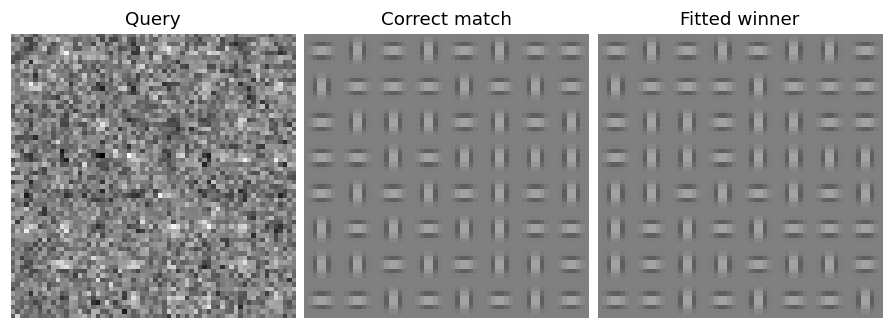

In [3]:
import json
if not (OUT/'fit.json').exists():
    run(OUT)
pairs=pd.read_csv(OUT/'profiles.csv')
decisions=pd.read_csv(OUT/'decisions.csv')
info=json.loads((OUT/'fit.json').read_text())
keys=['split','family','group','condition']
test=decisions[decisions.split=='test'].pivot(index=keys,columns='method',values='top1')
failure=test[(test['trained profile']<1)&(test[info['selected_single']]==1)]
key=failure.index[0]
group=pairs.set_index(keys).loc[[key]].sort_values('candidate')
weights=np.array([info['weights'][j] for j in COMPONENTS])
winner,runner,margin=explain(group,weights)
_,query,refs,truth=next(row for row in make_images() if row[0]==key)
assert winner!=truth
print('Selected gallery:',key)
print('Correct candidate:',truth,'· fitted winner:',winner,'· runner-up:',runner)
fig,axes=plt.subplots(1,3,figsize=(8,3))
limit=max(np.max(np.abs(query)),np.max(np.abs(refs)))
for ax,x,label in zip(axes,[query,refs[truth],refs[winner]],['Query','Correct match','Fitted winner']):
    ax.imshow(x,cmap='gray',vmin=-limit,vmax=limit);ax.set_title(label);ax.set_axis_off()
show('21_failure_gallery')

## Attribute the score difference exactly
The plotted component gap is $S_j(A,B_{winner})-S_j(A,B_{true})$. Positive values support the chosen candidate, negative values support the true candidate. Multiplying each gap by its fitted weight gives its exact additive contribution to the scalar score gap. For this case we compare the winner to the correct candidate even if it ranks below the runner-up.

,winner_agreement,weight,true_agreement,unweighted gap,weighted gap
orientation histogram,0.29143,0.0,0.29143,0.00000,0.00000
orientation pairs,0.06808,0.0,0.02872,0.03936,0.00000
orientation triplets,0.00919,0.0,0.01435,-0.00516,-0.00000
aligned orientation,0.23011,1.0,0.22948,0.00062,0.00062
intensity power,0.32039,0.0,0.31976,0.00063,0.00000
aligned sign-free pixels,0.32846,0.0,0.34239,-0.01394,-0.00000


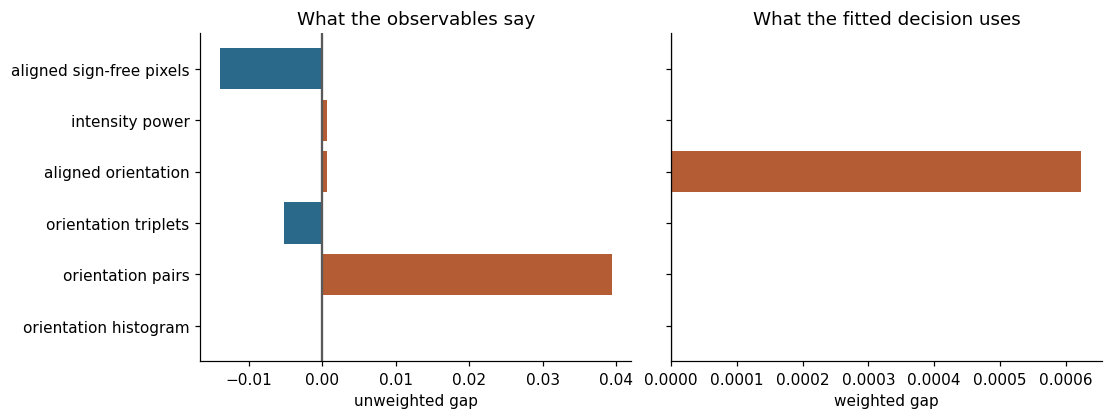

In [5]:
winner_card=weighted_similarity(similarity_profile(query,refs[winner]),weights)
true_card=weighted_similarity(similarity_profile(query,refs[truth]),weights)
card=winner_card.rename(columns={'agreement':'winner_agreement'}).drop(columns='contribution')
card['true_agreement']=true_card.agreement
card['unweighted gap']=card.winner_agreement-card.true_agreement
card['weighted gap']=card['unweighted gap']*weights
np.testing.assert_allclose(card['weighted gap'].sum(),winner_card.contribution.sum()-true_card.contribution.sum())
assert card['weighted gap'].sum()>0
display(card.round(5));card.to_csv(OUT/'failure_scorecard.csv')
fig,axes=plt.subplots(1,2,sharey=True,figsize=(10,3.7))
for ax,key_name in zip(axes,['unweighted gap','weighted gap']):
    vals=card[key_name]
    ax.barh(vals.index,vals,color=np.where(vals>=0,'#b45c34','#2b698a'))
    ax.axvline(0,color='.35');ax.set_xlabel(key_name)
axes[0].set_title('What the observables say')
axes[1].set_title('What the fitted decision uses')
show('21_failure_attribution')

## Specify the standard-image pilot
1. Use a public image panel with explicit retrieval labels. Source identity and semantic category require separate endpoints. Begin with controlled source copies and independently sourced distractors.
2. Choose an explicit representation and spatial geometry. Record resizing, boundary handling, gradient reliability, and registration. Compare fixed-grid and learned-patch inputs while preserving an image-only profile API.
3. Split by source before transformations. For category transfer, additionally hold out categories or defined visual families. Learn normalization and any weights on training sources. Choose among decision rules on development sources by the target endpoint.
4. Include alignment-aware baselines, difficult distractors and source-level confidence intervals. Export pair profiles and exact score contributions along with all retrieval outcomes.
5. Audit known changes in brightness, shape, texture and position before interpreting profile components as explanations of labels. Use labeled transformations and human judgments for perceptual claims.

The current scorecard gives an exact account of a fixed linear decision. It identifies which measured agreements favor each image. The scientific interpretation of those agreements depends on the representation and task.